# Embedding an image with EmbeddingGemma 2

A multimodal embedding model puts text and images into one 768-dimensional space

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from sentence_transformers import SentenceTransformer

## Load the model

Google recommends `bfloat16` or `float32`, never `float16`

In [2]:
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32

model = SentenceTransformer("google/embeddinggemma-2", model_kwargs={"torch_dtype": dtype})

print(model.get_embedding_dimension())

Loading weights:   0%|          | 0/1376 [00:00<?, ?it/s]

768


## Load one image

from the STL-10.

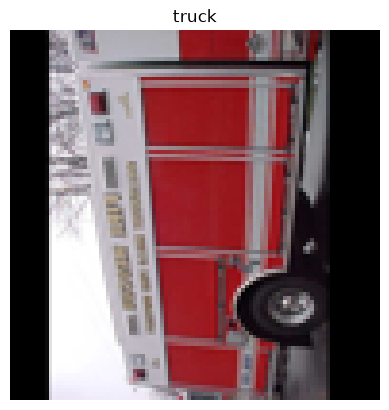

In [13]:
DATA = "../week_2/data/stl10_binary"

class_names = [l.strip() for l in open(f"{DATA}/class_names.txt") if l.strip()]

X = np.fromfile(f"{DATA}/test_X.bin", dtype=np.uint8).reshape(-1, 3, 96, 96)
y = np.fromfile(f"{DATA}/test_y.bin", dtype=np.uint8)

i = 34
img = Image.fromarray(X[i].transpose(1, 2, 0))

plt.imshow(img)
plt.title(class_names[y[i] - 1])
plt.axis("off")
plt.show()

## The embedding

An image goes in as a dict. No text prefix - the `task: ...` prefixes are for text only.

In [14]:
e = model.encode({"image": img}, normalize_embeddings=True)

print(e.shape, e.dtype)

(768,) float32


In [15]:
e.shape

(768,)

## Construct text from the class label

This is just to show that what a plain vision transformer cannot do. 
The image vector is compared against
the embedding of each class name.

In [16]:
texts = [f"a photo of a {c}" for c in class_names]

print (texts)

T = model.encode(texts, normalize_embeddings=True)

scores = e @ T.T

for rank in np.argsort(-scores)[:3]:
    print(f"{scores[rank]:+.3f}  {class_names[rank]}")

print(f"\ntrue class: {class_names[y[i] - 1]}")

['a photo of a airplane', 'a photo of a bird', 'a photo of a car', 'a photo of a cat', 'a photo of a deer', 'a photo of a dog', 'a photo of a horse', 'a photo of a monkey', 'a photo of a ship', 'a photo of a truck']
+0.656  truck
+0.606  car
+0.603  airplane

true class: truck
